# SECOM semiconductor yield analysis

In semiconductor manufacturing, each wafer passes through hundreds of process steps, and sensors record measurements at each one. If a production run fails the final quality test, engineers want to know which measurements could have warned them earlier.

The SECOM dataset (UCI Machine Learning Repository) has **1,567 production runs**, each with **590 anonymised sensor readings** and a label: pass (`-1`) or fail (`1`). The sensor names are hidden, so the goal is not to explain the physics but to:

1. Load the data and check its size, missing values and how many runs fail.
2. Clean it: remove unusable sensors and fill remaining gaps.
3. Find which sensors look most different between passing and failing runs.
4. Train a model to flag failing runs, and measure it properly given that failures are rare.
5. List the sensors the model relies on most and what a process engineer could do with that.

## 1. Load and inspect

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("images", exist_ok=True)
BLUE, ORANGE, GRID, AXIS = "#2a78d6", "#eb6834", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": AXIS,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 110, "font.size": 10,
})

# secom.data: one row per run, 590 numbers separated by spaces, no header row
X = pd.read_csv("data/secom.data", sep=" ", header=None)
X.columns = [f"s{i}" for i in range(X.shape[1])]        # name the sensors s0 ... s589

# secom_labels.data: the label (-1 pass, 1 fail) and a timestamp in quotes
labels = pd.read_csv("data/secom_labels.data", sep=" ", header=None, names=["label", "timestamp"])
labels["timestamp"] = pd.to_datetime(labels.timestamp, format="%d/%m/%Y %H:%M:%S")
y = (labels.label == 1).astype(int)                       # 1 = fail, 0 = pass (easier to read)

print("Sensor table:", X.shape, " Labels:", labels.shape)
print("Date range:", labels.timestamp.min().date(), "to", labels.timestamp.max().date())

Sensor table: (1567, 590)  Labels: (1567, 2)
Date range: 2008-07-19 to 2008-10-17


In [2]:
counts = y.value_counts().rename({0: "pass", 1: "fail"})
print(counts.to_string())
print(f"Fail rate: {100 * y.mean():.1f}%")

label
pass    1463
fail     104
Fail rate: 6.6%


In [3]:
missing_pct = X.isna().mean() * 100            # share of missing values in each sensor column
print(f"Total missing cells: {X.isna().sum().sum():,} of {X.size:,} ({100 * X.isna().values.mean():.1f}%)")
print(f"Sensors with no missing values:   {(missing_pct == 0).sum()}")
print(f"Sensors with more than 50% missing: {(missing_pct > 50).sum()}")
print(f"Sensors that never change value:  {(X.nunique() <= 1).sum()}")

Total missing cells: 41,951 of 924,530 (4.5%)
Sensors with no missing values:   52
Sensors with more than 50% missing: 28
Sensors that never change value:  116


**What this shows.** There are 1,567 runs recorded between 19 July and 17 October 2008. 104 failed (6.6%) and 1,463 passed, so the classes are very unbalanced. About 4.5% of all readings are missing. Only 52 of the 590 sensors have no gaps at all, 28 sensors are missing more than half their values, and 116 sensors report the same value for every run, so they carry no information.

## 2. Clean

Three steps:

- **Drop sensors with more than 50% missing values.** Filling in more than half of a column would mean making up most of it.
- **Drop sensors that never change** (one unique value). A constant reading cannot tell a pass from a fail.
- **Fill remaining gaps with the median** of that sensor. The median is used instead of the mean because a few extreme readings would pull the mean around.

One detail matters here: the medians are calculated **from the training data only**, after the train/test split in section 4. If the test data were used to calculate them, a little information about the test set would leak into training. Sections 2 and 3 only drop columns, which doesn't use the labels, so it is safe to do before the split.

In [4]:
keep = (missing_pct <= 50) & (X.nunique() > 1)     # True for sensors we keep
Xc = X.loc[:, keep]
print(f"Dropped {(~keep).sum()} sensors, kept {Xc.shape[1]}")
print(f"  more than 50% missing: {(missing_pct > 50).sum()}")
print(f"  constant:              {((missing_pct <= 50) & (X.nunique() <= 1)).sum()}")

Dropped 144 sensors, kept 446
  more than 50% missing: 28


  constant:              116


## 3. Which sensors differ most between passing and failing runs?

Each sensor is measured in different units, so comparing raw averages would be meaningless. Instead, for each sensor I calculate a **standardised difference**: (average in failing runs minus average in passing runs) divided by the sensor's overall standard deviation. A value of 0.5 means failing runs read half a standard deviation higher on average. Missing values are ignored in this step.

In [5]:
fail_mean = Xc[y == 1].mean()
pass_mean = Xc[y == 0].mean()
std_diff = ((fail_mean - pass_mean) / Xc.std()).rename("std_diff")
top_diff = std_diff.reindex(std_diff.abs().sort_values(ascending=False).index).head(10)
top_diff.round(3).to_frame()

,std_diff
s59,0.624
s103,0.607
s510,0.528
s348,0.519
s431,0.487
s434,0.452
s430,0.444
s435,0.440
s21,0.437
s28,-0.432


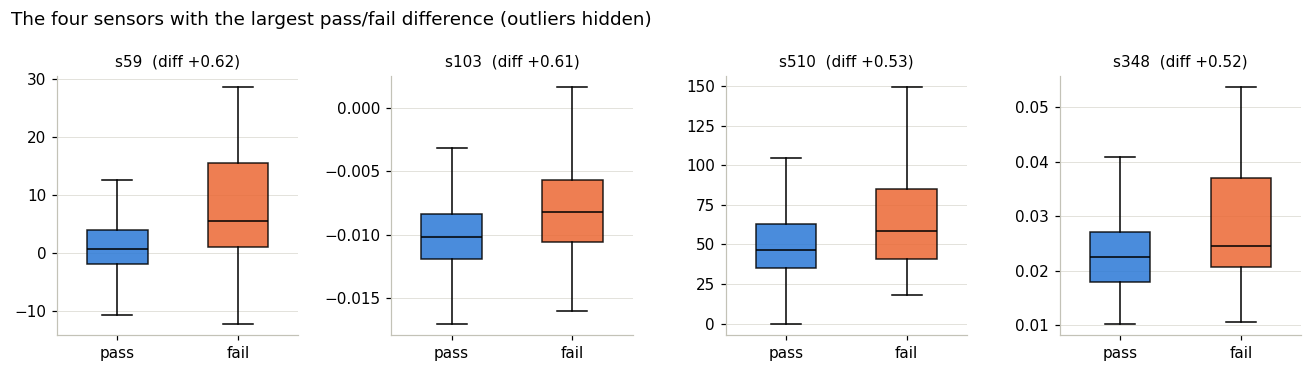

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, s in zip(axes, top_diff.index[:4]):
    data = [Xc.loc[y == 0, s].dropna(), Xc.loc[y == 1, s].dropna()]
    bp = ax.boxplot(data, tick_labels=["pass", "fail"], widths=0.5, patch_artist=True, showfliers=False,
                    medianprops=dict(color="black"))
    for patch, c in zip(bp["boxes"], [BLUE, ORANGE]):
        patch.set_facecolor(c); patch.set_alpha(0.85)
    ax.set_title(f"{s}  (diff {top_diff[s]:+.2f})", fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("The four sensors with the largest pass/fail difference (outliers hidden)", x=0.01, ha="left")
plt.tight_layout(); plt.savefig("images/top_sensor_boxplots.png"); plt.show()

**What this shows.** Sensors s59 and s103 stand out: failing runs read about 0.6 standard deviations higher than passing runs on both. The next group (s510, s348, s431) differ by about 0.5. These are modest gaps. The boxplots show that the pass and fail ranges overlap heavily for every sensor, so no single sensor can separate failing runs on its own. That is why a model that combines many sensors is worth trying.

## 4. Model: can we flag failing runs?

### Why accuracy is misleading here

Only about 7% of runs fail. A "model" that predicts **pass for every single run** would be right about 93% of the time while catching zero failures. So accuracy tells us almost nothing. What matters is:

- **Recall on the fail class:** of the runs that really failed, what share did the model catch?
- **Precision on the fail class:** of the runs the model flagged, what share really failed? (Low precision means many false alarms.)
- **The confusion matrix:** the four counts behind both numbers.

### Setup

- **Stratified train/test split (75/25):** "stratified" keeps the same 7% fail rate in both parts, which matters when there are only about 100 failures in total.
- **Random forest:** many decision trees, each trained on a random sample of runs and sensors, voting together. It copes with hundreds of features and doesn't need the data to be scaled.
- **`class_weight="balanced"`:** tells the model that mistakes on the rare fail class count about 14 times more (1,463 passes divided by 104 fails) than mistakes on passes, so it doesn't just learn to say "pass".

In [7]:
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, precision_recall_curve, recall_score, precision_score, accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    Xc, y, test_size=0.25, stratify=y, random_state=42)

medians = X_train.median()                 # medians from training data only
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print(f"Train: {len(y_train)} runs ({y_train.sum()} fails)   Test: {len(y_test)} runs ({y_test.sum()} fails)")

rf = RandomForestClassifier(n_estimators=500, class_weight="balanced", min_samples_leaf=3,
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

Train: 1175 runs (78 fails)   Test: 392 runs (26 fails)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [8]:
# Baseline: always predict pass
baseline = np.zeros(len(y_test), dtype=int)
print(f"Always-pass baseline  -> accuracy {accuracy_score(y_test, baseline):.1%}, fail recall {recall_score(y_test, baseline):.0%}")

# Random forest with the default rule: flag as fail if more than 50% of trees vote fail
pred_default = rf.predict(X_test)
print(f"Random forest (0.5)   -> accuracy {accuracy_score(y_test, pred_default):.1%}, "
      f"fail recall {recall_score(y_test, pred_default):.0%}, fail precision {precision_score(y_test, pred_default, zero_division=0):.0%}")
print("Confusion matrix (rows = actual pass/fail, columns = predicted pass/fail):")
print(confusion_matrix(y_test, pred_default))

proba_test = rf.predict_proba(X_test)[:, 1]   # share of trees voting 'fail' for each test run
print(f"\nROC AUC on test set: {roc_auc_score(y_test, proba_test):.3f}  (0.5 = random guessing, 1.0 = perfect ranking)")

Always-pass baseline  -> accuracy 93.4%, fail recall 0%


Random forest (0.5)   -> accuracy 93.4%, fail recall 0%, fail precision 0%
Confusion matrix (rows = actual pass/fail, columns = predicted pass/fail):
[[366   0]
 [ 26   0]]



ROC AUC on test set: 0.815  (0.5 = random guessing, 1.0 = perfect ranking)


**The default result proves the point about accuracy.** With the default 0.5 threshold, the random forest flags no runs at all as fails. Its accuracy (93.4%) is identical to the always-pass baseline and it catches 0 of the 26 failing test runs. Yet the ROC AUC of 0.815 shows the model does rank failing runs above passing runs most of the time; the scores for failing runs are higher, just rarely above 0.5.

### Choosing a better threshold

The model gives each run a score between 0 and 1 (the share of trees that vote "fail"). By default a run is flagged only if the score is above 0.5. For rare failures that is far too strict. Lowering the threshold catches more failures at the cost of more false alarms.

To pick the threshold **without looking at the test set**, I use 5-fold cross-validation on the training data: the training set is split into five parts, a model is trained on four and scores the fifth, five times over, so every training run gets an honest score. I then choose the threshold that maximises the F1 score (a balance of precision and recall) on those scores, and only then apply it to the test set once.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(
    RandomForestClassifier(n_estimators=500, class_weight="balanced", min_samples_leaf=3, random_state=42, n_jobs=-1),
    X_train, y_train, cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = np.argmax(f1[:-1])
threshold = thr[best]
print(f"Chosen threshold from cross-validation: {threshold:.3f}")

pred = (proba_test >= threshold).astype(int)
cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nTest set with threshold {threshold:.3f}:")
print(f"  accuracy        {accuracy_score(y_test, pred):.1%}")
print(f"  fail recall     {recall_score(y_test, pred):.0%}  ({tp} of {tp + fn} failing runs caught)")
print(f"  fail precision  {precision_score(y_test, pred):.0%}  ({tp} of {tp + fp} flagged runs were real fails)")
print(f"  false alarms    {fp} of {tn + fp} passing runs")
print()
print(classification_report(y_test, pred, target_names=["pass", "fail"]))

Chosen threshold from cross-validation: 0.282

Test set with threshold 0.282:
  accuracy        90.1%
  fail recall     35%  (9 of 26 failing runs caught)
  fail precision  29%  (9 of 31 flagged runs were real fails)
  false alarms    22 of 366 passing runs

              precision    recall  f1-score   support

        pass       0.95      0.94      0.95       366
        fail       0.29      0.35      0.32        26

    accuracy                           0.90       392
   macro avg       0.62      0.64      0.63       392
weighted avg       0.91      0.90      0.90       392



In [10]:
# Trade-off table: what happens at different thresholds on the test set
rows = []
for t in [0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1]:
    p = (proba_test >= t).astype(int)
    rows.append({"threshold": t, "fails_caught": int(((p == 1) & (y_test == 1)).sum()),
                 "false_alarms": int(((p == 1) & (y_test == 0)).sum()),
                 "fail_recall": round(recall_score(y_test, p), 2),
                 "fail_precision": round(precision_score(y_test, p, zero_division=0), 2)})
pd.DataFrame(rows)

,threshold,fails_caught,false_alarms,fail_recall,fail_precision
0,0.50,0,0,0.00,0.00
1,0.40,1,5,0.04,0.17
2,0.30,8,18,0.31,0.31
3,0.25,14,44,0.54,0.24
4,0.20,19,95,0.73,0.17
5,0.15,24,186,0.92,0.11
6,0.10,26,308,1.00,0.08


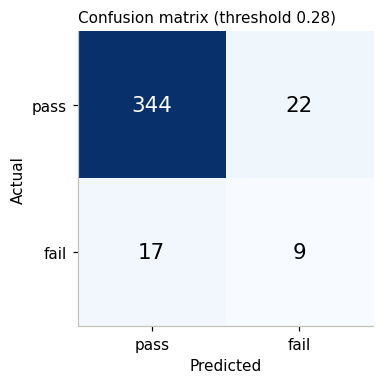

In [11]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha="center", va="center", fontsize=14,
            color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["pass", "fail"]); ax.set_yticks([0, 1], ["pass", "fail"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.grid(False)
ax.set_title(f"Confusion matrix (threshold {threshold:.2f})", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig("images/confusion_matrix.png"); plt.show()

**Result.** Using the threshold of 0.28 chosen by cross-validation, the model catches 9 of the 26 failing runs in the test set (35% recall), and 9 of the 31 runs it flags are real failures (29% precision), with 22 false alarms out of 366 passing runs. Accuracy drops slightly to 90.1%, which is the right trade: we gave up a little accuracy to catch failures that the baseline misses completely. The trade-off table shows how a factory could tune this. At a threshold of 0.20 the model would catch 19 of 26 failures (73%) but raise 95 false alarms. Which point is right depends on cost: if a missed failure means scrapping an expensive batch while a false alarm only means an extra inspection, a lower threshold makes sense. This is a modest model, which is typical for SECOM, but it is clearly better than catching nothing.

## 5. The 10 sensors the model relies on most

A random forest records how much each sensor helped its trees separate passes from fails (its "importance"). I list the top 10 and check whether they overlap with the sensors found in section 3.

In [12]:
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top10 = importance.head(10).to_frame("importance")
top10["std_diff"] = std_diff[top10.index].round(2)
top10["in_top10_by_difference"] = top10.index.isin(top_diff.index)
top10["importance"] = top10.importance.round(4)
print(f"Top 10 sensors carry {100 * importance.head(10).sum():.1f}% of total importance across {len(importance)} sensors")
top10

Top 10 sensors carry 11.5% of total importance across 446 sensors


,importance,std_diff,in_top10_by_difference
s59,0.0178,0.62,True
s103,0.0170,0.61,True
s33,0.0134,0.32,False
s477,0.0105,0.23,False
s31,0.0099,-0.20,False
s65,0.0097,0.22,False
s130,0.0095,0.31,False
s64,0.0094,0.31,False
s213,0.0088,0.18,False
s519,0.0086,0.25,False


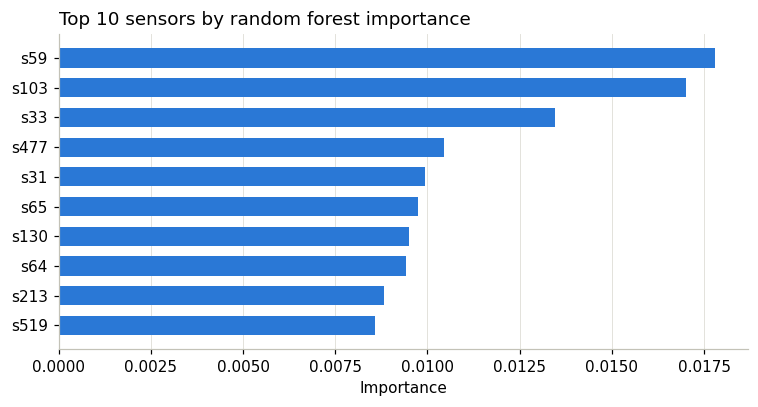

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.8))
d = importance.head(10).iloc[::-1]
ax.barh(d.index, d.values, color=BLUE, height=0.65)
ax.set_title("Top 10 sensors by random forest importance", loc="left")
ax.set_xlabel("Importance")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("images/top10_importance.png"); plt.show()

**What this would mean for a process engineer.** The two sensors with the largest pass/fail difference in section 3, s59 and s103, are also the two the model uses most, so both methods point to the same place. The other eight (s33, s477, s31, s65, s130, s64, s213, s519) did not stand out on their own but help in combination with other sensors. Importance is spread thinly: the top 10 sensors carry only 11.5% of the total across 446 sensors, which suggests failures come from many small effects rather than one broken step. For a process engineer, the practical use is a short watch-list: find which process steps s59 and s103 belong to, check whether their readings drift before failing runs, and consider tighter control limits or an alarm on them. Because the sensor names are hidden, this is where data work hands over to process knowledge.

## Summary and limitations

- 1,567 runs, 6.6% fail. After dropping 144 unusable sensors (28 mostly missing, 116 constant), 446 remain.
- No single sensor separates pass from fail; the largest differences are about 0.6 standard deviations (s59, s103).
- A random forest with balanced class weights reaches ROC AUC 0.815. At the default threshold it catches no failures, which shows why accuracy (93.4%) is misleading here.
- With a threshold of 0.28 chosen by cross-validation, it catches 9 of 26 failing test runs (35% recall) with 29% precision. Lowering the threshold to 0.20 would catch 73% of failures at the cost of more false alarms.
- s59 and s103 come out on top in both the simple comparison and the model, so they are the first sensors an engineer should investigate.

**Limitations**

- The sensor names are anonymised, so the results can't be linked to specific process steps or physical causes.
- With only about 26 failing runs in the test set, each one caught or missed changes recall by about 4 percentage points, so the numbers are rough.
- The split is random rather than by time. In a real factory the model would be trained on past runs and used on future ones, and the process can drift over time, so a time-based split would be a fairer test.
- Random forest importance can spread credit between sensors that are strongly correlated with each other, so a sensor missing from the top 10 is not necessarily unimportant.

**With more time** I would try a time-based split, remove highly correlated sensors before modelling, compare against a simpler logistic regression, and use permutation importance to double-check the top sensors.